# Entrega 3 · Modelado — ¿Gana el underdog? (versión corregida)

**Pregunta de investigación**: ¿ganará el equipo no favorito (*underdog*) el próximo partido, según las métricas previas
del encuentro y de sus jugadores?

Parte del Silver que produce el DAG (`include/data/silver/underdog_dataset.parquet`, 17.959 partidos × 31 columnas) y elige
**el modelo que usa la aplicación de la Entrega 4**. Se corre de arriba hacia abajo, con una semilla en la primera celda.

### Qué cambió desde la defensa de la Entrega 3

| Lo que nos marcaron | Qué hicimos | Dónde |
|---|---|---|
| Elegir un modelo mejor: el de una sola columna era «la cuota con otro nombre» | Medimos los modelos también **en plata**. El de una columna nunca encuentra una apuesta; el de 12 columnas (con jugadores) sí | Partes 5 y 6 |
| Medirlo desde lo económico: ¿sirve para decidir, o da lo mismo que mirar las casas? | Simulación de apuestas con las cuotas reales, por pedazo y con intervalo de confianza | Parte 5 |
| Barrido de hiperparámetros también para los otros modelos, no solo la logística | Curvas de validación para las cuatro familias, en la misma escala | Parte 3.3 |
| Gráficos comparados con escalas distintas, y barridos «hacia el infinito» sin sentido | Todos los gráficos de AUC usan el mismo eje (0,50–0,70). Los barridos van solo por rangos razonables | Partes 3 y 4 |
| En las tablas de diferencias, agregar la diferencia porcentual | Cada tabla de comparación trae la diferencia absoluta y la relativa (%) | Partes 3, 4 y 5 |

### Hoja de ruta

| Parte | Qué pasa |
|---|---|
| 1 | El planteo: qué predecimos, las métricas, la partición y la validación |
| 2 | El piso y el rival (el mercado) |
| 3 | La comparación de cuatro familias, con barridos de hiperparámetros |
| 4 | Las columnas: qué aporta cada grupo |
| 5 | **La plata**: ¿el modelo sirve para tomar una decisión? |
| 6 | La elección del modelo final |
| 7 | El modelo final, medido una vez sobre el test |
| 8 | Fuga, lo que no anduvo y el modelo guardado para la app |

In [1]:
# La semilla, definida una sola vez y pasada a todo lo que la acepte
SEMILLA = 42

import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(SEMILLA)
RNG = np.random.default_rng(SEMILLA)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold"})

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from include.config import AUDIT_DIR, DATA_DIR, SILVER_DATASET_PATH
from include.src.columns import FEATURE_COLUMNS, TARGET_COLUMN

import sklearn
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

# La misma escala en todos los gráficos de AUC, y los mismos colores en todo el proyecto (también en la app)
AUC_LIM = (0.50, 0.70)
COLOR = {"modelo": "#0f8b7d", "mercado": "#e08a1e", "piso": "#8a8f98", "todos": "#c0392b",
         "train": "#3b6fb6", "validacion": "#0f8b7d"}

scikit-learn 1.9.1 | pandas 2.3.3


In [2]:
# Nombres legibles para tablas y gráficos. "Dif." = underdog − favorito: positivo quiere decir que el underdog es mejor.
NOMBRES = {
    "prob_no_favorito": "Prob. implícita del underdog", "prob_draw": "Prob. implícita del empate",
    "nofav_xi_overall_mean_gap": "Dif. rating medio del XI", "nofav_top3_overall_gap": "Dif. rating de los 3 mejores",
    "nofav_best_overall_gap": "Dif. mejor jugador", "nofav_worst_overall_gap": "Dif. peor titular",
    "nofav_def_overall_gap": "Dif. rating de la defensa", "nofav_mid_overall_gap": "Dif. rating del mediocampo",
    "nofav_att_overall_gap": "Dif. rating del ataque", "nofav_best_finishing_gap": "Dif. mejor definición",
    "nofav_best_reactions_gap": "Dif. mejores reacciones", "nofav_best_marking_gap": "Dif. mejor marca",
    "nofav_gk_overall_gap": "Dif. rating del arquero", "nofav_fastest_sprint_speed_gap": "Dif. jugador más rápido",
    "nofav_strongest_strength_gap": "Dif. jugador más fuerte", "nofav_overall_std_gap": "Dif. dispersión del XI",
    "nofav_xi_age_mean_gap": "Dif. edad media del XI", "nofav_xi_height_mean_gap": "Dif. altura media del XI",
    "jornada": "Jornada", "liga": "Liga", "equipo_favorito": "Favorito local / visitante",
}
CLASES = ["No ganó el underdog", "Ganó el underdog"]
MERCADO   = ["prob_no_favorito", "prob_draw"]
JUGADORES = [c for c in FEATURE_COLUMNS if c not in MERCADO]
ROJAS_NUM = ["nofav_gk_overall_gap", "nofav_fastest_sprint_speed_gap", "nofav_strongest_strength_gap",
             "nofav_overall_std_gap", "nofav_xi_age_mean_gap", "nofav_xi_height_mean_gap", "jornada"]
ROJAS_CAT = ["liga", "equipo_favorito"]

def legible(columnas):
    return [NOMBRES.get(c, c) for c in columnas]

def con_porcentaje(tabla, columna, referencia, nombre="% vs referencia"):
    '''Agrega la diferencia relativa (en %) de una columna contra el valor de una fila de referencia.'''
    base = tabla.loc[referencia, columna]
    tabla[nombre] = (100 * (tabla[columna] - base) / abs(base)).round(2)
    return tabla

## Parte 1 — El planteo

### 1.1 Qué predecimos

Una fila = un partido. El objetivo es `gano_no_favorito`: 1 si ganó el underdog, 0 si empató o perdió. El *underdog* es el
equipo con menor probabilidad implícita de ganar según las cuotas pre-partido (solo partidos con diferencia > 0,05 con el
favorito). Es **clasificación binaria**. Además del Silver, se leen de la auditoría las **cuotas reales** de cada partido: no son
una feature (el modelo usa la probabilidad que ya está en Silver), sirven para medir **cuánta plata** gana o pierde una decisión.

In [3]:
df = (pd.read_parquet(SILVER_DATASET_PATH)
        .merge(pd.read_parquet(AUDIT_DIR / "match_audit.parquet",
                               columns=["match_id", "odds_home", "odds_away", "equipo_local", "equipo_visitante",
                                        "goles_local", "goles_visitante"]), on="match_id")
        .sort_values(["fecha", "match_id"]).reset_index(drop=True))
df[TARGET_COLUMN] = df[TARGET_COLUMN].astype(int)
# la cuota que paga una apuesta al underdog (decimal: por cada $1 apostado se cobra cuota si gana)
df["cuota_underdog"] = np.where(df["equipo_favorito"] == "local", df["odds_away"], df["odds_home"])

print(f"{df.shape[0]:,} partidos, del {df['fecha'].min():%d/%m/%Y} al {df['fecha'].max():%d/%m/%Y}")
(df[TARGET_COLUMN].value_counts().rename(index=dict(enumerate(CLASES)))
   .to_frame("partidos").assign(proporcion=lambda t: (t["partidos"] / t["partidos"].sum()).round(4)))

17,959 partidos, del 09/08/2008 al 17/05/2016


,partidos,proporcion
gano_no_favorito,,
No ganó el underdog,14305,0.7965
Ganó el underdog,3654,0.2035


### 1.2 Las métricas, declaradas antes de elegir

Hay dos preguntas distintas, y cada una tiene su métrica:

1. **¿El modelo ordena bien los partidos?** → **ROC-AUC** (principal) y **log-loss** (secundaria). La accuracy no sirve: decir
   siempre «no gana» acierta el 80% sin mirar nada. La AUC mide si el modelo le da más chance a los partidos que el underdog
   ganó; la log-loss, si las probabilidades son creíbles.
2. **¿El modelo sirve para tomar una decisión?** → **ROI** (retorno por peso apostado). La decisión es apostar $1 al underdog
   **solo cuando el modelo cree que la cuota paga de más**: cuando `probabilidad del modelo × cuota − 1 > 0` (valor esperado
   positivo). El ROI es lo que se gana o pierde por cada peso apostado. Es la pregunta que hace la corrección: si el modelo no
   cambia ninguna decisión, da lo mismo que mirar las casas de apuestas.

Las dos van juntas: un modelo que ordena igual que el mercado pero no apuesta nunca no le sirve a nadie, y uno que apuesta
mucho pero ordena peor está adivinando.

### 1.3 La partición y la validación imitan el uso

Los partidos están en el tiempo y la aplicación predice partidos que todavía no se jugaron. El **test es la temporada 2015/16
completa**, y no se mira hasta la Parte 7. Adentro del entrenamiento (2008/09 a 2014/15) todo se elige con
**`TimeSeriesSplit(5)`**: cada pedazo se entrena con lo anterior y se valida con el bloque siguiente.

In [4]:
from sklearn.model_selection import TimeSeriesSplit

TEST_TEMPORADA = "2015/2016"
CANDIDATAS = FEATURE_COLUMNS + ROJAS_NUM + ROJAS_CAT
entrenamiento = df[df["temporada"] != TEST_TEMPORADA].reset_index(drop=True)
prueba        = df[df["temporada"] == TEST_TEMPORADA].reset_index(drop=True)
X_train, y_train = entrenamiento[CANDIDATAS], entrenamiento[TARGET_COLUMN]
X_test,  y_test  = prueba[CANDIDATAS],        prueba[TARGET_COLUMN]

cv = TimeSeriesSplit(n_splits=5)
PEDAZOS = list(cv.split(X_train))

pd.DataFrame([{"entrena con": f"{len(tr):,}", "valida desde": entrenamiento["fecha"].iloc[va].min().date(),
               "valida hasta": entrenamiento["fecha"].iloc[va].max().date(), "valida con": f"{len(va):,}",
               "casa de apuestas": entrenamiento["odds_source"].iloc[va].mode()[0],
               "% gana underdog": round(100 * y_train.iloc[va].mean(), 1)}
              for tr, va in PEDAZOS], index=[f"pedazo {i}" for i in range(1, 6)])

,entrena con,valida desde,valida hasta,valida con,casa de apuestas,% gana underdog
pedazo 1,"2,595",2010-01-10,2011-02-13,"2,593",B365,19.5
pedazo 2,"5,188",2011-02-13,2012-03-18,"2,593",B365,19.8
pedazo 3,"7,781",2012-03-18,2013-03-30,"2,593",PS,21.2
pedazo 4,"10,374",2013-03-30,2014-04-27,"2,593",PS,19.7
pedazo 5,"12,967",2014-04-27,2015-05-31,"2,593",PS,20.4


**Todo adentro de un pipeline.** Elegir columnas, pasar las probabilidades a `logit` (la escala natural de la logística: con
ella, «creerle al mercado» es coeficiente 1), imputar con la mediana y escalar van adentro del objeto que se entrena.

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.base import clone
from include.src.features import logit      # en el paquete: el modelo guardado la necesita para cargarse

PROBABILIDADES = ["prob_no_favorito", "prob_draw"]

def armar(modelo, numericas=FEATURE_COLUMNS, categoricas=(), logit_prob=True):
    '''elegir columnas -> logit de las probabilidades / imputar + escalar el resto / one-hot -> modelo.'''
    probs = [c for c in numericas if logit_prob and c in PROBABILIDADES]
    resto = [c for c in numericas if c not in probs]
    ramas = []
    if probs:
        ramas.append(("prob", Pipeline([("imputar", SimpleImputer(strategy="median")),
                                        ("logit", FunctionTransformer(logit, feature_names_out="one-to-one"))]), probs))
    if resto:
        ramas.append(("num", Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())]), resto))
    if categoricas:
        ramas.append(("cat", OneHotEncoder(handle_unknown="ignore"), list(categoricas)))
    return Pipeline([("preparar", ColumnTransformer(ramas, remainder="drop")), ("modelo", modelo)])

METRICAS = {"auc": "roc_auc", "logloss": "neg_log_loss", "accuracy": "accuracy"}

def evaluar(pipeline, X=X_train, y=y_train, validacion=cv):
    r = cross_validate(pipeline, X, y, cv=validacion, scoring=METRICAS, return_train_score=True, n_jobs=-1)
    return {"AUC media": r["test_auc"].mean(), "AUC desvío": r["test_auc"].std(), "AUC train": r["train_auc"].mean(),
            "log-loss media": -r["test_logloss"].mean(), "log-loss desvío": r["test_logloss"].std(),
            "accuracy media": r["test_accuracy"].mean(), "_por_pedazo": r["test_auc"]}

def tabla(resultados):
    return pd.DataFrame(resultados).T.drop(columns="_por_pedazo").astype(float).round(4)

## Parte 2 — El piso y el rival

**El piso**: `DummyClassifier`, que le da a todos los partidos la tasa de victorias del entrenamiento. **El rival real**: la
probabilidad del mercado tal cual, sin entrenar nada. Un modelo que no la supere no sabe más que las casas de apuestas.

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, log_loss

resultados = {"Piso (Dummy)": evaluar(armar(DummyClassifier(strategy="prior")))}
cuota = np.array([(roc_auc_score(y_train.iloc[va], X_train["prob_no_favorito"].iloc[va]),
                   log_loss(y_train.iloc[va], X_train["prob_no_favorito"].iloc[va])) for _, va in PEDAZOS]).T
resultados["Mercado (prob. tal cual)"] = {"AUC media": cuota[0].mean(), "AUC desvío": cuota[0].std(), "AUC train": np.nan,
                                          "log-loss media": cuota[1].mean(), "log-loss desvío": cuota[1].std(),
                                          "accuracy media": np.nan, "_por_pedazo": cuota[0]}
tabla(resultados)

,AUC media,AUC desvío,AUC train,log-loss media,log-loss desvío,accuracy media
Piso (Dummy),0.500,0.0000,0.5,0.5020,0.0084,0.7988
Mercado (prob. tal cual),0.637,0.0105,NaN,0.4813,0.0085,NaN


El piso da **AUC 0,5** y **accuracy 0,80** (la prueba de que la accuracy no servía). El mercado ordena bastante mejor que el
piso y su log-loss es la vara más alta.

## Parte 3 — La comparación

### 3.1 Cuatro familias, cada una con su grilla

Regresión logística (la referencia simple), árbol de decisión, random forest y gradient boosting, con **las mismas 12
columnas** y la **misma validación temporal**. Cada familia busca su mejor versión con una grilla.

In [7]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

familias = {
    "Regresión logística": (LogisticRegression(max_iter=3000), {"modelo__C": [0.001, 0.01, 0.1, 1, 10]}),
    "Árbol de decisión":   (DecisionTreeClassifier(random_state=SEMILLA),
                            {"modelo__max_depth": [2, 3, 4, 5, 6, 8], "modelo__min_samples_leaf": [20, 100]}),
    "Random forest":       (RandomForestClassifier(n_estimators=300, random_state=SEMILLA, n_jobs=1),
                            {"modelo__max_depth": [3, 4, 6, 8], "modelo__min_samples_leaf": [20, 100]}),
    "Gradient boosting":   (HistGradientBoostingClassifier(random_state=SEMILLA, early_stopping=False),
                            {"modelo__learning_rate": [0.03, 0.1], "modelo__max_depth": [2, 3], "modelo__max_iter": [50, 100, 300]}),
}
busquedas = {n: GridSearchCV(armar(m), g, cv=cv, scoring=METRICAS, refit="auc", return_train_score=True, n_jobs=-1)
                 .fit(X_train, y_train) for n, (m, g) in familias.items()}

def mejor_de(b):
    r, i = b.cv_results_, b.best_index_
    return {"AUC media": r["mean_test_auc"][i], "AUC desvío": r["std_test_auc"][i], "AUC train": r["mean_train_auc"][i],
            "log-loss media": -r["mean_test_logloss"][i], "log-loss desvío": r["std_test_logloss"][i],
            "accuracy media": r["mean_test_accuracy"][i],
            "_por_pedazo": np.array([r[f"split{k}_test_auc"][i] for k in range(cv.n_splits)])}

for n, b in busquedas.items():
    resultados[n] = mejor_de(b)
comparacion = tabla(resultados)
comparacion["brecha train − validación"] = (comparacion["AUC train"] - comparacion["AUC media"]).round(4)
comparacion["Δ AUC vs logística"] = (comparacion["AUC media"] - comparacion.loc["Regresión logística", "AUC media"]).round(4)
comparacion = con_porcentaje(comparacion, "AUC media", "Regresión logística", "Δ AUC % vs logística")
display(pd.DataFrame({n: {k.split("__")[-1]: v for k, v in b.best_params_.items()} for n, b in busquedas.items()}).T
          .rename_axis("mejores hiperparámetros"))
comparacion.sort_values("AUC media", ascending=False)

,C,max_depth,min_samples_leaf,learning_rate,max_iter
mejores hiperparámetros,,,,,
Regresión logística,1.0,NaN,NaN,NaN,NaN
Árbol de decisión,NaN,2.0,20.0,NaN,NaN
Random forest,NaN,4.0,20.0,NaN,NaN
Gradient boosting,NaN,2.0,NaN,0.03,50.0


,AUC media,AUC desvío,AUC train,log-loss media,log-loss desvío,accuracy media,brecha train − validación,Δ AUC vs logística,Δ AUC % vs logística
Mercado (prob. tal cual),0.6370,0.0105,NaN,0.4813,0.0085,NaN,NaN,0.0009,0.14
Regresión logística,0.6361,0.0092,0.6336,0.4815,0.0089,0.7988,-0.0025,0.0000,0.00
Gradient boosting,0.6331,0.0124,0.6433,0.4838,0.0087,0.7988,0.0102,-0.0030,-0.47
Random forest,0.6321,0.0126,0.6763,0.4832,0.0087,0.7988,0.0442,-0.0040,-0.63
Árbol de decisión,0.6242,0.0114,0.6257,0.4832,0.0090,0.7988,0.0015,-0.0119,-1.87
Piso (Dummy),0.5000,0.0000,0.5000,0.5020,0.0084,0.7988,0.0000,-0.1361,-21.40


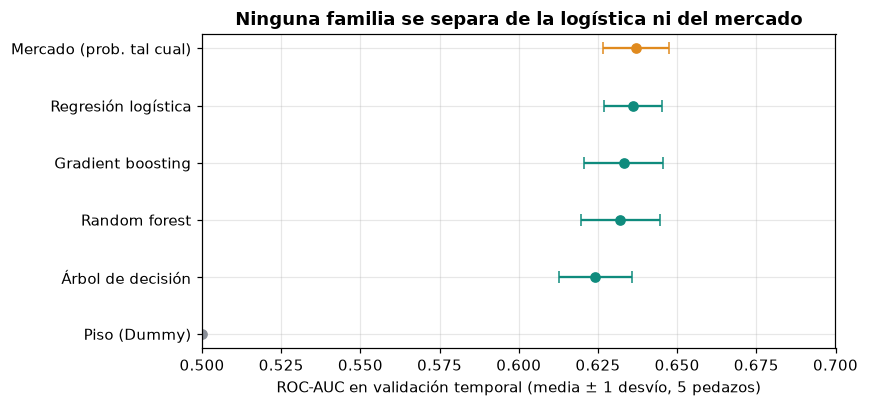

In [8]:
orden = comparacion.sort_values("AUC media").index
fig, ax = plt.subplots(figsize=(8, 3.8))
colores = [COLOR["mercado"] if "Mercado" in n else COLOR["piso"] if "Piso" in n else COLOR["modelo"] for n in orden]
for i, n in enumerate(orden):
    ax.errorbar(comparacion.loc[n, "AUC media"], i, xerr=comparacion.loc[n, "AUC desvío"], fmt="o", capsize=4, color=colores[i])
ax.set_yticks(range(len(orden)), orden)
ax.set_xlim(*AUC_LIM)
ax.set_xlabel("ROC-AUC en validación temporal (media ± 1 desvío, 5 pedazos)")
ax.set_title("Ninguna familia se separa de la logística ni del mercado")
plt.tight_layout(); plt.show()

### 3.2 La regla: el complejo tiene que ganarle al simple por más que el desvío

In [9]:
ref = resultados["Regresión logística"]
regla = pd.DataFrame({n: {
    "Δ AUC vs logística": resultados[n]["AUC media"] - ref["AUC media"],
    "Δ % vs logística": 100 * (resultados[n]["AUC media"] - ref["AUC media"]) / ref["AUC media"],
    "mayor desvío": max(resultados[n]["AUC desvío"], ref["AUC desvío"]),
    "pedazos en que gana": f"{int((resultados[n]['_por_pedazo'] > ref['_por_pedazo']).sum())} de 5",
    "¿gana por más que el desvío?": "sí" if resultados[n]["AUC media"] - ref["AUC media"] > max(resultados[n]["AUC desvío"], ref["AUC desvío"]) else "no",
} for n in ["Árbol de decisión", "Random forest", "Gradient boosting"]}).T
regla

,Δ AUC vs logística,Δ % vs logística,mayor desvío,pedazos en que gana,¿gana por más que el desvío?
Árbol de decisión,-0.011929,-1.875299,0.011437,0 de 5,no
Random forest,-0.004035,-0.634389,0.012613,2 de 5,no
Gradient boosting,-0.003009,-0.473113,0.012372,1 de 5,no


### 3.3 Barridos de hiperparámetros: las cuatro familias, en la misma escala

Un hiperparámetro por familia, el que controla su complejidad, en un rango que tiene sentido (sin barrer «hacia el infinito»:
más allá de esos valores el modelo ya memorizó o ya no cambia). Los cuatro paneles comparten el eje vertical (AUC 0,50–0,70),
así se comparan entre sí a simple vista. El punto marcado es el elegido por la grilla.

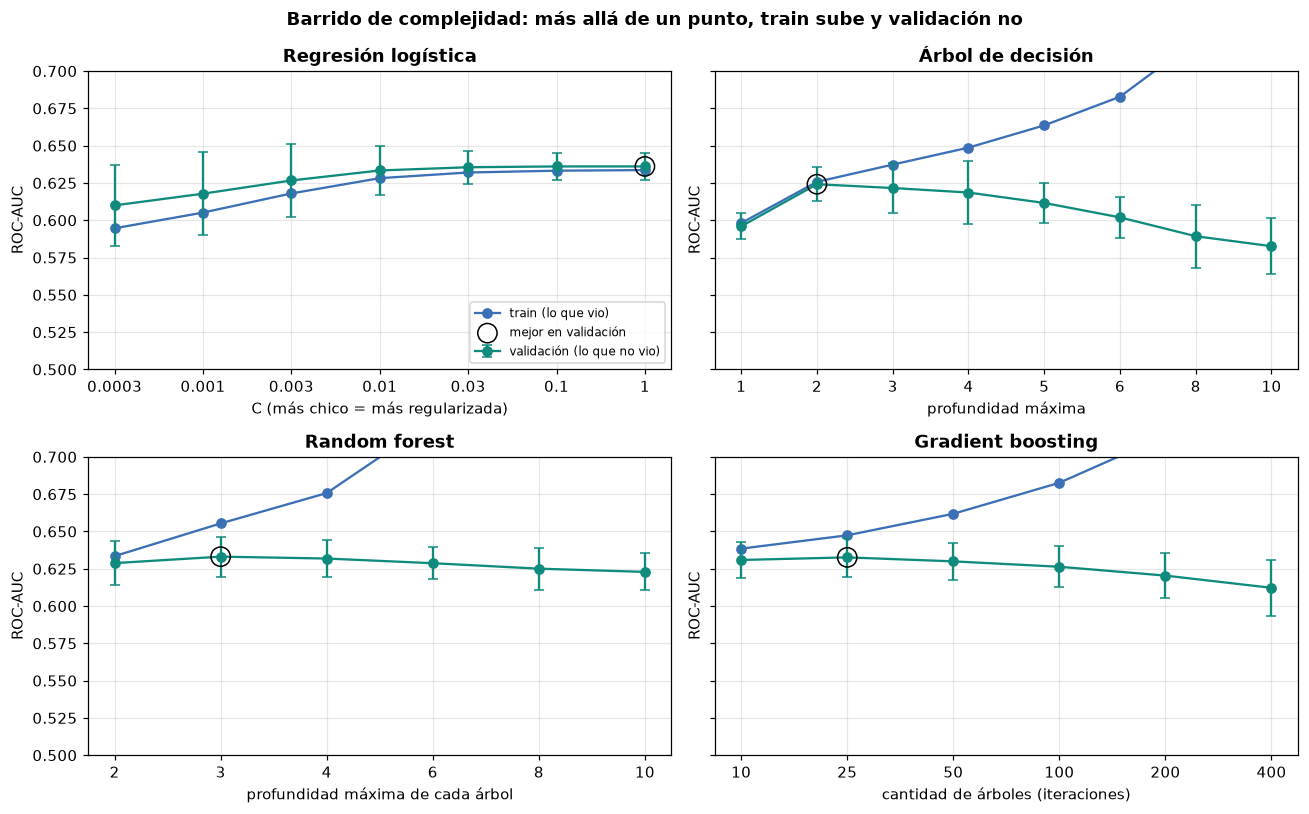

train  validación  desvío
Regresión logística 0.0003  0.5946      0.6100  0.0270
                    0.001   0.6051      0.6178  0.0276
                    0.003   0.6180      0.6267  0.0246
                    0.01    0.6282      0.6334  0.0166
                    0.03    0.6320      0.6355  0.0110
                    0.1     0.6332      0.6361  0.0092
                    1       0.6336      0.6361  0.0092
Árbol de decisión   1       0.5981      0.5960  0.0086
                    2       0.6257      0.6242  0.0114
                    3       0.6373      0.6216  0.0170
                    4       0.6487      0.6186  0.0210
                    5       0.6636      0.6116  0.0132
                    6       0.6828      0.6019  0.0137
                    8       0.7205      0.5893  0.0211
                    10      0.7519      0.5826  0.0187
Random forest       2       0.6335      0.6288  0.0145
                    3       0.6554      0.6331  0.0134
                    4       0.6757      0.6319  0.0125
                    6       0.7239      0.6287  0.0109
                    8       0.7742      0.6251  0.0141
                    10      0.8154      0.6229  0.0124
Gradient boosting   10      0.6385      0.6309  0.0120
                    25      0.6474      0.6326  0.0129
                    50      0.6618      0.6300  0.0122
                    100     0.6826      0.6263  0.0138
                    200     0.7141      0.6204  0.0153
                    400     0.7569      0.6122  0.0186

In [10]:
from sklearn.model_selection import validation_curve

barridos = [
    ("Regresión logística", LogisticRegression(max_iter=3000), "modelo__C", [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 1],
     "C (más chico = más regularizada)"),
    ("Árbol de decisión", DecisionTreeClassifier(min_samples_leaf=20, random_state=SEMILLA), "modelo__max_depth",
     [1, 2, 3, 4, 5, 6, 8, 10], "profundidad máxima"),
    ("Random forest", RandomForestClassifier(n_estimators=200, min_samples_leaf=20, random_state=SEMILLA, n_jobs=1),
     "modelo__max_depth", [2, 3, 4, 6, 8, 10], "profundidad máxima de cada árbol"),
    ("Gradient boosting", HistGradientBoostingClassifier(max_depth=2, learning_rate=0.1, random_state=SEMILLA, early_stopping=False),
     "modelo__max_iter", [10, 25, 50, 100, 200, 400], "cantidad de árboles (iteraciones)"),
]
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharey=True)
curvas = {}
for ax, (nombre, modelo, param, valores, etiqueta) in zip(axes.flat, barridos):
    tr, va = validation_curve(armar(modelo), X_train, y_train, param_name=param, param_range=valores,
                              cv=cv, scoring="roc_auc", n_jobs=-1)
    x = [str(v) for v in valores]
    ax.plot(x, tr.mean(1), "o-", color=COLOR["train"], label="train (lo que vio)")
    ax.errorbar(x, va.mean(1), yerr=va.std(1), fmt="o-", capsize=3, color=COLOR["validacion"], label="validación (lo que no vio)")
    mejor = int(np.argmax(va.mean(1)))
    ax.scatter([x[mejor]], [va.mean(1)[mejor]], s=160, facecolors="none", edgecolors="black", zorder=5, label="mejor en validación")
    ax.set_ylim(*AUC_LIM); ax.set_title(nombre); ax.set_xlabel(etiqueta); ax.set_ylabel("ROC-AUC")
    curvas[nombre] = pd.DataFrame({"train": tr.mean(1), "validación": va.mean(1), "desvío": va.std(1)}, index=x).round(4)
axes[0, 0].legend(fontsize=8, loc="lower right")
fig.suptitle("Barrido de complejidad: más allá de un punto, train sube y validación no", fontweight="bold")
plt.tight_layout(); plt.show()
pd.concat(curvas)

**Cómo se lee.** En las cuatro familias pasa lo mismo: la validación sube hasta una complejidad baja y después se estanca o
cae, mientras train sigue subiendo. El árbol después de profundidad 2, el bosque después de 3 y el boosting después de
25 iteraciones empiezan a memorizar partidos. **La logística no tiene brecha** en ningún valor de C: el problema es casi
lineal en la cuota, y los modelos flexibles solo pueden encontrar interacciones que no existen.

### 3.4 ¿Y si los pedazos se armaran al azar?

In [11]:
from sklearn.model_selection import StratifiedKFold

cv_azar = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
azar = pd.DataFrame({n: {"AUC temporal": resultados[n]["AUC media"],
                         "AUC al azar": evaluar(busquedas[n].best_estimator_, validacion=cv_azar)["AUC media"]}
                     for n in busquedas}).T
azar["al azar − temporal"] = azar["AUC al azar"] - azar["AUC temporal"]
azar["Δ %"] = 100 * azar["al azar − temporal"] / azar["AUC temporal"]
azar.round(4)

,AUC temporal,AUC al azar,al azar − temporal,Δ %
Regresión logística,0.6361,0.6335,-0.0025,-0.3989
Árbol de decisión,0.6242,0.6172,-0.0070,-1.1143
Random forest,0.6321,0.6291,-0.0029,-0.4608
Gradient boosting,0.6331,0.6332,0.0002,0.0261


Al azar el número **no sube** (diferencias de milésimas): ninguna columna identifica al equipo ni a la fecha. La validación
temporal sigue siendo la correcta porque imita el uso, y este resultado funciona además como chequeo de fuga.

## Parte 4 — Las columnas: qué aporta cada grupo

Con la logística (la familia que la Parte 3 deja como referencia), cuatro conjuntos de columnas y la diferencia **pareada**
por pedazo contra el mercado solo.

In [12]:
def logistica(numericas, categoricas=(), C=1.0):
    return armar(LogisticRegression(max_iter=3000, C=C), numericas=numericas, categoricas=categoricas)

grupos = {
    "Solo prob. del underdog (1)": evaluar(logistica(["prob_no_favorito"])),
    "Solo mercado (2)":            evaluar(logistica(MERCADO)),
    "Solo jugadores (10)":         evaluar(logistica(JUGADORES)),
    "Mercado + jugadores (12)":    evaluar(logistica(FEATURE_COLUMNS)),
}
base = grupos["Solo prob. del underdog (1)"]
t_grupos = pd.DataFrame({n: {"AUC media": r["AUC media"], "AUC desvío": r["AUC desvío"], "log-loss media": r["log-loss media"],
                             "Δ AUC vs prob. sola": (r["_por_pedazo"] - base["_por_pedazo"]).mean(),
                             "desvío de Δ": (r["_por_pedazo"] - base["_por_pedazo"]).std()}
                         for n, r in grupos.items()}).T
con_porcentaje(t_grupos, "AUC media", "Solo prob. del underdog (1)", "Δ AUC % vs prob. sola").round(4)

,AUC media,AUC desvío,log-loss media,Δ AUC vs prob. sola,desvío de Δ,Δ AUC % vs prob. sola
Solo prob. del underdog (1),0.6370,0.0105,0.4813,0.0000,0.0000,0.00
Solo mercado (2),0.6363,0.0103,0.4813,-0.0007,0.0008,-0.11
Solo jugadores (10),0.5986,0.0242,0.4924,-0.0384,0.0173,-6.02
Mercado + jugadores (12),0.6361,0.0092,0.4815,-0.0009,0.0027,-0.14


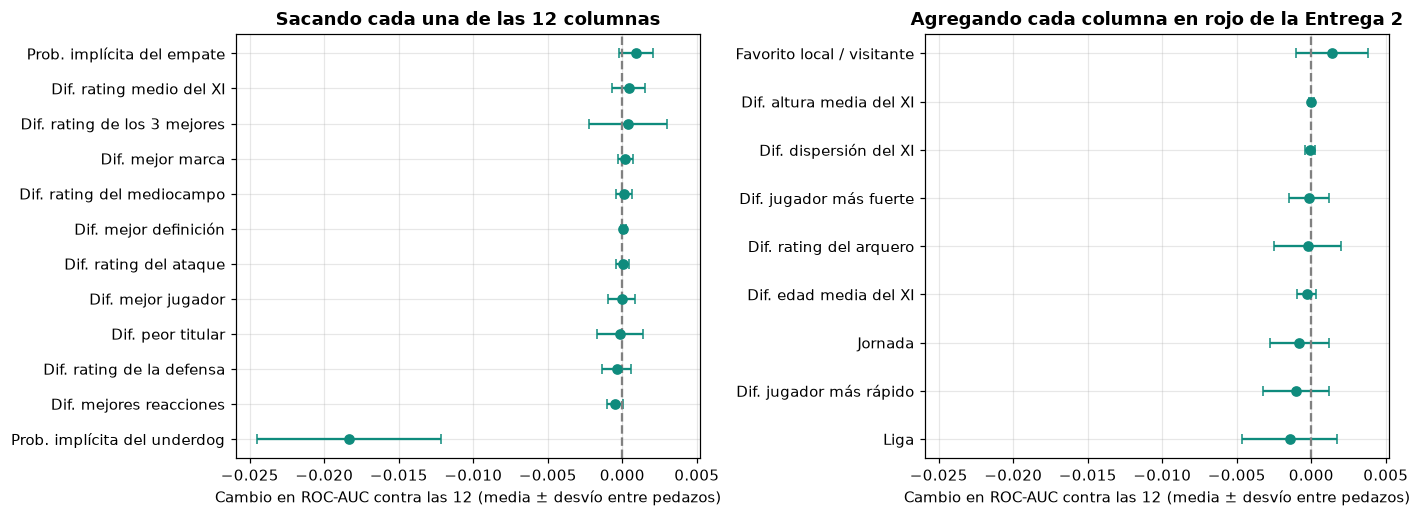

,Δ AUC,Δ %,desvío de Δ,pedazos en que mejora
Prob. implícita del underdog,-0.018328,-2.881342,0.006189,0 de 5
Dif. mejores reacciones,-0.000516,-0.081096,0.000532,1 de 5
Dif. rating de la defensa,-0.00039,-0.061342,0.000942,2 de 5
Dif. peor titular,-0.00015,-0.023617,0.001531,2 de 5
Dif. mejor jugador,-0.000035,-0.005458,0.000893,2 de 5
Dif. rating del ataque,0.000035,0.005544,0.000436,2 de 5
Dif. mejor definición,0.000061,0.009538,0.000173,3 de 5
Dif. rating del mediocampo,0.000119,0.018685,0.000519,3 de 5
Dif. mejor marca,0.000213,0.033528,0.000499,3 de 5
Dif. rating de los 3 mejores,0.000384,0.060351,0.00263,4 de 5


,Δ AUC,Δ %,desvío de Δ,pedazos en que mejora
Favorito local / visitante,0.001387,0.217974,0.002439,3 de 5
Dif. altura media del XI,-0.000004,-0.000552,0.000153,3 de 5
Dif. dispersión del XI,-0.000065,-0.010278,0.000347,2 de 5
Dif. jugador más fuerte,-0.000179,-0.028071,0.001334,2 de 5
Dif. rating del arquero,-0.000249,-0.039223,0.002254,3 de 5
Dif. edad media del XI,-0.00032,-0.050309,0.000614,2 de 5
Jornada,-0.000796,-0.125145,0.001975,3 de 5
Dif. jugador más rápido,-0.001026,-0.16128,0.002196,3 de 5
Liga,-0.001439,-0.22618,0.003183,1 de 5


In [13]:
base_12 = grupos["Mercado + jugadores (12)"]
def delta(r):
    d = r["_por_pedazo"] - base_12["_por_pedazo"]
    return {"Δ AUC": d.mean(), "Δ %": 100 * d.mean() / base_12["AUC media"], "desvío de Δ": d.std(),
            "pedazos en que mejora": f"{int((d > 0).sum())} de 5"}

sacar = pd.DataFrame({NOMBRES[c]: delta(evaluar(logistica([x for x in FEATURE_COLUMNS if x != c]))) for c in FEATURE_COLUMNS}).T
agregar = {NOMBRES[c]: delta(evaluar(logistica(FEATURE_COLUMNS + [c]))) for c in ROJAS_NUM}
agregar.update({NOMBRES[c]: delta(evaluar(logistica(FEATURE_COLUMNS, categoricas=[c]))) for c in ROJAS_CAT})
agregar = pd.DataFrame(agregar).T

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True)
for ax, t, titulo in [(axes[0], sacar, "Sacando cada una de las 12 columnas"),
                      (axes[1], agregar, "Agregando cada columna en rojo de la Entrega 2")]:
    t = t.sort_values("Δ AUC")
    ax.errorbar(t["Δ AUC"].astype(float), range(len(t)), xerr=t["desvío de Δ"].astype(float), fmt="o", capsize=3, color=COLOR["modelo"])
    ax.axvline(0, color="gray", linestyle="--")
    ax.set_yticks(range(len(t)), t.index); ax.set_title(titulo)
    ax.set_xlabel("Cambio en ROC-AUC contra las 12 (media ± desvío entre pedazos)")
plt.tight_layout(); plt.show()
display(sacar.sort_values("Δ AUC").round(4)); agregar.sort_values("Δ AUC", ascending=False).round(4)

**Por AUC, los jugadores no suman sobre el mercado**: todas las diferencias están dentro del desvío. Solos ordenan (AUC ~0,60),
pero las cuotas ya incorporan quién es mejor equipo. Si la única pregunta fuera «¿ordena mejor?», la regla de parsimonia
dejaría una sola columna. La Parte 5 muestra por qué esa no es la única pregunta.

## Parte 5 — La plata: ¿el modelo sirve para tomar una decisión?

**La decisión**: antes de cada partido, apostar $100 al underdog **solo si el modelo cree que la cuota paga de más**, es decir
si `p_modelo × cuota − 1 > 0`. Se cobra `100 × cuota` si gana y se pierden los $100 si no. Se usan las cuotas reales de la
casa que eligió el pipeline (Bet365 hasta 2011/12, Pinnacle desde 2012/13), que **traen el margen de la casa adentro**.

Se compara contra dos estrategias de referencia:

- **Apostar a todos los underdogs**: el piso económico. Pierde aproximadamente el margen de la casa.
- **El mercado como modelo** (la logística con la probabilidad sola): como aprende «creerle a la cuota», su probabilidad nunca
  supera a la que paga la casa, así que **nunca encuentra una apuesta**. Su ROI es 0, pero no toma ninguna decisión.

Todo se mide con predicciones **fuera de muestra** de la validación temporal: cada partido recibe la probabilidad de un modelo
que solo vio el pasado. El intervalo de confianza del ROI sale de un *bootstrap* (2.000 remuestreos de las apuestas).

In [14]:
APUESTA = 100

def fuera_de_muestra(pipeline):
    '''Probabilidad de cada partido de validación, de un modelo entrenado solo con los pedazos anteriores.'''
    proba = pd.Series(np.nan, index=X_train.index)
    for tr, va in PEDAZOS:
        proba.iloc[va] = clone(pipeline).fit(X_train.iloc[tr], y_train.iloc[tr]).predict_proba(X_train.iloc[va])[:, 1]
    return proba.dropna()

def apuestas(proba, datos, margen=0.0):
    '''Las apuestas que haría la regla y lo que gana cada una (en pesos).'''
    d = datos.loc[proba.index]
    valor = proba * d["cuota_underdog"] - 1
    elegidas = d[valor > margen]
    return APUESTA * (elegidas["cuota_underdog"] * elegidas[TARGET_COLUMN] - 1)

def intervalo(ganancias, B=2000):
    if len(ganancias) == 0:
        return (np.nan, np.nan)
    medias = RNG.choice(ganancias.values, size=(B, len(ganancias))).mean(1)
    return tuple(np.percentile(medias, [2.5, 97.5]) / APUESTA)

def resumen_plata(ganancias, total_partidos):
    lo, hi = intervalo(ganancias)
    return {"apuestas": len(ganancias), "% de partidos": 100 * len(ganancias) / total_partidos,
            "apostado ($)": APUESTA * len(ganancias), "ganancia ($)": ganancias.sum(),
            "ROI %": 100 * ganancias.mean() / APUESTA if len(ganancias) else 0.0,
            "IC 95% ROI": f"[{100*lo:+.1f}%, {100*hi:+.1f}%]" if len(ganancias) else "—"}

candidatos_plata = {
    "Mercado (logística, prob. sola)":   logistica(["prob_no_favorito"]),
    "Logística mercado + jugadores (12)": logistica(FEATURE_COLUMNS, C=busquedas["Regresión logística"].best_params_["modelo__C"]),
    "Random forest (12)":                busquedas["Random forest"].best_estimator_,
    "Gradient boosting (12)":            busquedas["Gradient boosting"].best_estimator_,
}
oof = {n: fuera_de_muestra(p) for n, p in candidatos_plata.items()}
validacion = entrenamiento.loc[oof["Mercado (logística, prob. sola)"].index]
n_val = len(validacion)

plata = {"Apostar a todos los underdogs": resumen_plata(APUESTA * (validacion["cuota_underdog"] * validacion[TARGET_COLUMN] - 1), n_val)}
plata.update({n: resumen_plata(apuestas(p, entrenamiento), n_val) for n, p in oof.items()})
plata = pd.DataFrame(plata).T
plata["Δ ROI vs apostar a todos (puntos)"] = plata["ROI %"].astype(float) - plata.loc["Apostar a todos los underdogs", "ROI %"]
plata.round(2)

,apuestas,% de partidos,apostado ($),ganancia ($),ROI %,IC 95% ROI,Δ ROI vs apostar a todos (puntos)
Apostar a todos los underdogs,12965,100.0,1296500,-99342.0,-7.662322,"[-11.3%, -4.1%]",0.00
"Mercado (logística, prob. sola)",0,0.0,0,0.0,0.0,—,7.66
Logística mercado + jugadores (12),1396,10.767451,139600,1061.0,0.760029,"[-10.7%, +12.7%]",8.42
Random forest (12),3112,24.003085,311200,-24745.0,-7.951478,"[-17.1%, +1.4%]",-0.29
Gradient boosting (12),4480,34.55457,448000,-39373.0,-8.788616,"[-17.1%, -1.1%]",-1.13


In [15]:
# por pedazo: ¿el resultado es estable o depende de una temporada?
por_pedazo = {}
for i, (_, va) in enumerate(PEDAZOS, start=1):
    idx = entrenamiento.index[va]
    d = entrenamiento.loc[idx]
    fila = {"casa": d["odds_source"].mode()[0],
            "todos los underdogs": 100 * (d["cuota_underdog"] * d[TARGET_COLUMN] - 1).mean()}
    for n in ["Logística mercado + jugadores (12)", "Random forest (12)", "Gradient boosting (12)"]:
        g = apuestas(oof[n].loc[idx], entrenamiento)
        fila[n] = 100 * g.mean() / APUESTA if len(g) else np.nan
    por_pedazo[f"pedazo {i}"] = fila
pd.DataFrame(por_pedazo).T.round(1).rename_axis("ROI % por pedazo")

,casa,todos los underdogs,Logística mercado + jugadores (12),Random forest (12),Gradient boosting (12)
ROI % por pedazo,,,,,
pedazo 1,B365,-13.132279,21.466667,-27.165354,-20.106686
pedazo 2,B365,-10.523718,-4.184685,-13.890306,-15.144928
pedazo 3,PS,-2.425376,0.493197,4.233151,4.401826
pedazo 4,PS,-8.665253,-13.182898,-11.209677,-12.517842
pedazo 5,PS,-3.564983,15.305764,2.397484,-4.012241


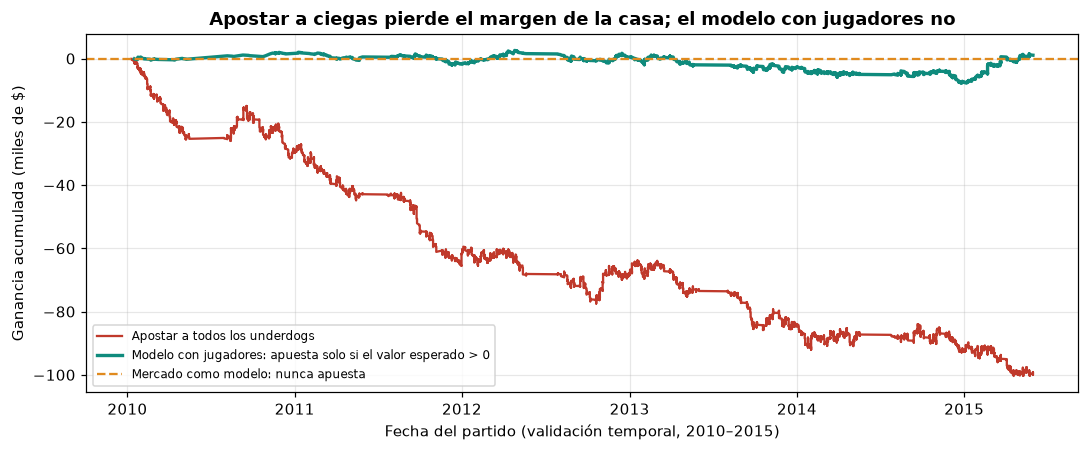

In [16]:
# la plata acumulada en el tiempo: cada estrategia apuesta $100 por partido elegido
fig, ax = plt.subplots(figsize=(10, 4.2))
todas = APUESTA * (validacion["cuota_underdog"] * validacion[TARGET_COLUMN] - 1)
ax.plot(validacion["fecha"], todas.cumsum() / 1000, color=COLOR["todos"], label="Apostar a todos los underdogs")
g = apuestas(oof["Logística mercado + jugadores (12)"], entrenamiento)
ax.plot(entrenamiento.loc[g.index, "fecha"], g.cumsum() / 1000, color=COLOR["modelo"], linewidth=2.2,
        label="Modelo con jugadores: apuesta solo si el valor esperado > 0")
ax.axhline(0, color=COLOR["mercado"], linestyle="--", label="Mercado como modelo: nunca apuesta")
ax.set_xlabel("Fecha del partido (validación temporal, 2010–2015)")
ax.set_ylabel("Ganancia acumulada (miles de $)")
ax.set_title("Apostar a ciegas pierde el margen de la casa; el modelo con jugadores no")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

In [17]:
# ¿y si se exige más valor esperado antes de apostar? (sensibilidad de la regla)
sens = {}
for m in [0.0, 0.02, 0.05, 0.10]:
    sens[f"valor esperado > {m:.2f}"] = resumen_plata(apuestas(oof["Logística mercado + jugadores (12)"], entrenamiento, margen=m), n_val)
pd.DataFrame(sens).T.round(2)

,apuestas,% de partidos,apostado ($),ganancia ($),ROI %,IC 95% ROI
valor esperado > 0.00,1396,10.767451,139600,1061.0,0.760029,"[-10.5%, +12.4%]"
valor esperado > 0.02,924,7.12688,92400,2365.0,2.559524,"[-11.6%, +17.1%]"
valor esperado > 0.05,465,3.586579,46500,-3117.0,-6.703226,"[-25.9%, +13.6%]"
valor esperado > 0.10,146,1.126109,14600,1697.0,11.623288,"[-23.9%, +51.7%]"


**Cómo se lee.**

- Apostar a ciegas a todos los underdogs **pierde ~7,7%** de lo apostado, y el intervalo no toca el cero: es el margen de la casa.
- El **mercado como modelo nunca apuesta**: no pierde, pero tampoco decide nada. Es exactamente la crítica de la corrección:
  da lo mismo que mirar las cuotas.
- La **logística con jugadores** apuesta en ~1 de cada 10 partidos y queda **cerca de empatar** (ROI apenas positivo). **Su
  intervalo incluye el cero**: no demuestra ganancia. Lo que sí demuestra es que los ratings de los titulares **le sacan el margen
  de la casa a la apuesta**: eligen partidos donde la cuota del underdog paga lo justo o un poco más.
- **Random forest y boosting** apuestan más y pierden casi lo mismo que apostar a ciegas: su probabilidad está peor calibrada,
  y en plata eso se paga.
- El resultado **varía mucho por pedazo** y con el margen exigido. Con pocas apuestas, un par de sorpresas lo mueven. Es una señal
  chica, y la contamos como tal.

## Parte 6 — La elección del modelo final

| Criterio | Mercado (prob. sola) | Logística con jugadores (12) | Random forest / boosting |
|---|---|---|---|
| AUC (ordenar partidos) | empate (dentro del desvío) | empate (dentro del desvío) | empate o peor |
| ¿Toma decisiones? | **no, nunca apuesta** | sí, ~1 de cada 10 partidos | sí |
| ROI de esas decisiones | — | **≈ 0** (IC incluye 0) | ≈ −7% (como apostar a ciegas) |
| Usa a los jugadores (la pregunta del proyecto) | no | **sí** | sí |
| Se puede llevar al navegador (Entrega 4) | sí | **sí (una fórmula)** | no |

**Elegimos la regresión logística con las 12 columnas** (mercado + jugadores). Ordena igual que el mercado, y es el único
modelo que, usando a los jugadores, **cambia decisiones sin perder plata**. La versión anterior eligió la columna sola porque
miraba solo la AUC. Con la pregunta económica, esa elección quedaba vacía: un modelo que nunca dice nada distinto de la
cuota no sirve para decidir.

In [18]:
from sklearn.metrics import precision_score, recall_score, f1_score

C_FINAL = busquedas["Regresión logística"].best_params_["modelo__C"]
COLUMNAS_FINALES = FEATURE_COLUMNS
final = logistica(COLUMNAS_FINALES, C=C_FINAL)
validacion_final = evaluar(final)

# class_weight: la otra palanca del desbalance. Cambia las probabilidades, y la regla de apuesta las usa tal cual
con_peso = armar(LogisticRegression(max_iter=3000, C=C_FINAL, class_weight="balanced"), numericas=COLUMNAS_FINALES)
oof_peso = fuera_de_muestra(con_peso)
pd.DataFrame({
    "sin peso (elegido)": {"AUC": validacion_final["AUC media"], "log-loss": validacion_final["log-loss media"],
                           "prob. media predicha": oof["Logística mercado + jugadores (12)"].mean(),
                           **{k: v for k, v in resumen_plata(apuestas(oof["Logística mercado + jugadores (12)"], entrenamiento), n_val).items()
                              if k in ("apuestas", "ROI %")}},
    "class_weight=balanced": {"AUC": roc_auc_score(y_train.loc[oof_peso.index], oof_peso),
                              "log-loss": log_loss(y_train.loc[oof_peso.index], oof_peso),
                              "prob. media predicha": oof_peso.mean(),
                              **{k: v for k, v in resumen_plata(apuestas(oof_peso, entrenamiento), n_val).items() if k in ("apuestas", "ROI %")}},
}).T.round(4)

,AUC,log-loss,prob. media predicha,apuestas,ROI %
sin peso (elegido),0.6361,0.4815,0.1958,1396.0,0.7600
class_weight=balanced,0.6358,0.6549,0.4744,12965.0,-7.6623


**Desbalance.** `class_weight="balanced"` deja la AUC igual pero infla las probabilidades (la media sube de ~0,20 a ~0,48). Con
la regla de valor esperado eso es grave: el modelo cree que todos los underdogs pagan de más, apuesta en **todos** los
partidos y pierde exactamente lo mismo que apostar a ciegas. **No se usa.** La decisión de sí/no no es un umbral fijo: es comparar la probabilidad
del modelo con la cuota de cada partido.

## Parte 7 — El modelo final, medido una vez sobre el test

Se entrena con todo 2008/09–2014/15 y se mide **una sola vez** sobre 2015/16, junto con las referencias.

In [19]:
modelo_final = clone(final).fit(X_train, y_train)
proba_test = pd.Series(modelo_final.predict_proba(X_test)[:, 1], index=X_test.index)
piso_test = armar(DummyClassifier(strategy="prior")).fit(X_train, y_train).predict_proba(X_test)[:, 1]

g_test = apuestas(proba_test, prueba)
todas_test = APUESTA * (prueba["cuota_underdog"] * prueba[TARGET_COLUMN] - 1)
test_tabla = pd.DataFrame({
    "Piso (Dummy)":            {"AUC": 0.5, "log-loss": log_loss(y_test, piso_test), **resumen_plata(todas_test, len(prueba))},
    "Mercado (prob. tal cual)": {"AUC": roc_auc_score(y_test, X_test["prob_no_favorito"]),
                                 "log-loss": log_loss(y_test, X_test["prob_no_favorito"]), "apuestas": 0, "ROI %": 0.0},
    "MODELO FINAL":            {"AUC": roc_auc_score(y_test, proba_test), "log-loss": log_loss(y_test, proba_test),
                                **resumen_plata(g_test, len(prueba))},
}).T
test_tabla.loc["Piso (Dummy)", "apuestas"] = f"{len(prueba)} (todas)"
display(test_tabla)
pd.DataFrame({"validación temporal": {"AUC": validacion_final["AUC media"], "AUC desvío": validacion_final["AUC desvío"],
                                      "log-loss": validacion_final["log-loss media"]},
              "test 2015/16": {"AUC": roc_auc_score(y_test, proba_test), "AUC desvío": np.nan, "log-loss": log_loss(y_test, proba_test)}}).T.round(4)

,AUC,log-loss,apuestas,% de partidos,apostado ($),ganancia ($),ROI %,IC 95% ROI
Piso (Dummy),0.5,0.529312,2399 (todas),100.0,239900,-2250.0,-0.937891,"[-9.7%, +7.7%]"
Mercado (prob. tal cual),0.656393,0.498332,0.0,NaN,NaN,NaN,0.0,NaN
MODELO FINAL,0.659924,0.498068,404,16.84035,40400,2672.0,6.613861,"[-14.4%, +29.9%]"


,AUC,AUC desvío,log-loss
validación temporal,0.6361,0.0092,0.4815
test 2015/16,0.6599,NaN,0.4981


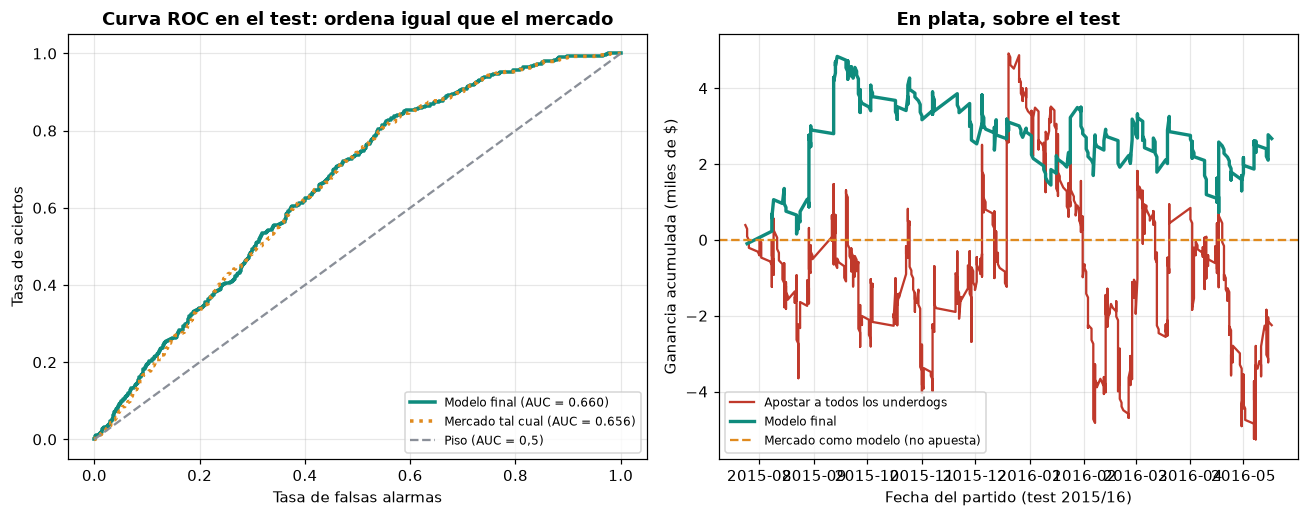

In [20]:
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay, classification_report

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for puntaje, nombre, color, estilo in [(proba_test, "Modelo final", COLOR["modelo"], "-"),
                                        (X_test["prob_no_favorito"], "Mercado tal cual", COLOR["mercado"], ":")]:
    fpr, tpr, _ = roc_curve(y_test, puntaje)
    axes[0].plot(fpr, tpr, estilo, color=color, linewidth=2.3, label=f"{nombre} (AUC = {roc_auc_score(y_test, puntaje):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color=COLOR["piso"], label="Piso (AUC = 0,5)")
axes[0].set_xlabel("Tasa de falsas alarmas"); axes[0].set_ylabel("Tasa de aciertos")
axes[0].set_title("Curva ROC en el test: ordena igual que el mercado"); axes[0].legend(fontsize=8, loc="lower right")

axes[1].plot(prueba["fecha"], todas_test.cumsum() / 1000, color=COLOR["todos"], label="Apostar a todos los underdogs")
axes[1].plot(prueba.loc[g_test.index, "fecha"], g_test.cumsum() / 1000, color=COLOR["modelo"], linewidth=2.2, label="Modelo final")
axes[1].axhline(0, color=COLOR["mercado"], linestyle="--", label="Mercado como modelo (no apuesta)")
axes[1].set_xlabel("Fecha del partido (test 2015/16)"); axes[1].set_ylabel("Ganancia acumulada (miles de $)")
axes[1].set_title("En plata, sobre el test"); axes[1].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

### 7.1 Dónde se equivoca

La decisión del modelo es «apostar» o «no apostar». La matriz cruza esa decisión con lo que pasó, normalizada por fila (de lo
que pasó, qué decidimos) y por columna (de lo que decidimos, qué pasó).

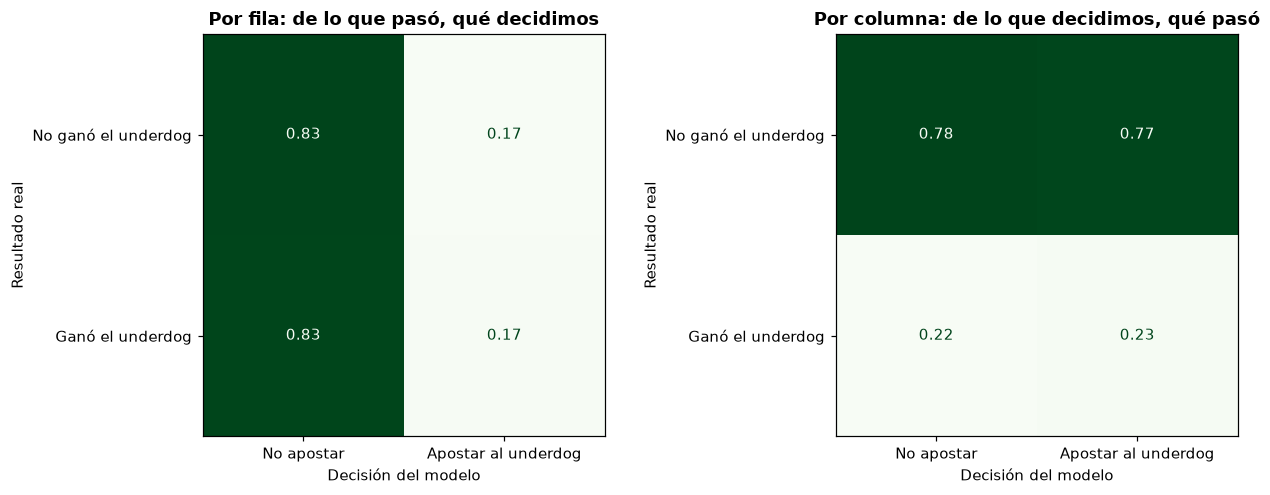

              precision    recall  f1-score   support

     No ganó      0.780     0.833     0.805      1869
        Ganó      0.225     0.172     0.195       530

    accuracy                          0.687      2399
   macro avg      0.503     0.502     0.500      2399
weighted avg      0.657     0.687     0.671      2399



In [21]:
decision = (proba_test * prueba["cuota_underdog"] - 1 > 0).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, norm, titulo in [(axes[0], "true", "Por fila: de lo que pasó, qué decidimos"),
                         (axes[1], "pred", "Por columna: de lo que decidimos, qué pasó")]:
    ConfusionMatrixDisplay.from_predictions(y_test, decision, normalize=norm, display_labels=CLASES, values_format=".2f",
                                            cmap="Greens", ax=ax, colorbar=False)
    ax.set_xticklabels(["No apostar", "Apostar al underdog"]); ax.grid(False)
    ax.set_title(titulo); ax.set_xlabel("Decisión del modelo"); ax.set_ylabel("Resultado real")
plt.tight_layout(); plt.show()
print(classification_report(y_test, decision, target_names=["No ganó", "Ganó"], digits=3))

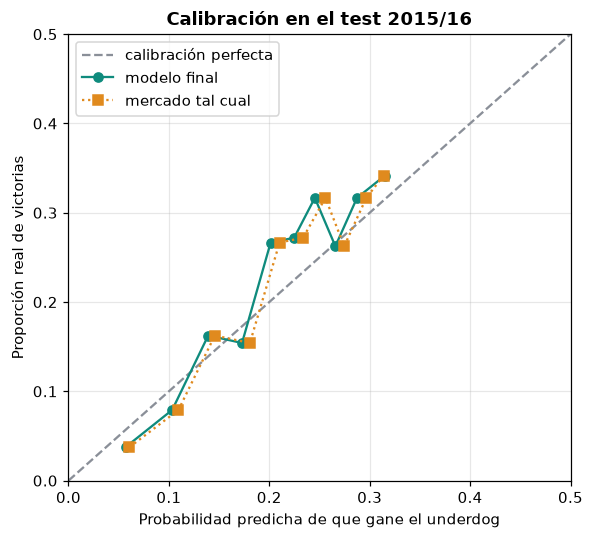

,partidos,prob. del modelo,prob. del mercado,tasa real
decil de prob. del modelo,,,,
2–8%,240,0.057,0.061,0.038
8–12%,240,0.103,0.110,0.079
12–16%,240,0.139,0.146,0.162
16–19%,240,0.173,0.181,0.154
19–21%,240,0.201,0.210,0.267
21–24%,239,0.225,0.234,0.272
24–26%,240,0.245,0.256,0.317
26–28%,240,0.266,0.275,0.262
28–30%,240,0.287,0.297,0.317


In [22]:
# calibración: el valor esperado depende de que la probabilidad sea creíble
tramos = pd.qcut(proba_test, 10)
tramos = tramos.cat.rename_categories([f"{100*i.left:.0f}–{100*i.right:.0f}%" for i in tramos.cat.categories])
calib = pd.DataFrame({"partidos": y_test.groupby(tramos.values, observed=True).size(),
                      "prob. del modelo": proba_test.groupby(tramos.values, observed=True).mean(),
                      "prob. del mercado": prueba["prob_no_favorito"].groupby(tramos.values, observed=True).mean(),
                      "tasa real": y_test.groupby(tramos.values, observed=True).mean()})
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 0.5], [0, 0.5], "--", color=COLOR["piso"], label="calibración perfecta")
ax.plot(calib["prob. del modelo"], calib["tasa real"], "o-", color=COLOR["modelo"], label="modelo final")
ax.plot(calib["prob. del mercado"], calib["tasa real"], "s:", color=COLOR["mercado"], label="mercado tal cual")
ax.set_xlim(0, 0.5); ax.set_ylim(0, 0.5)
ax.set_xlabel("Probabilidad predicha de que gane el underdog"); ax.set_ylabel("Proporción real de victorias")
ax.set_title("Calibración en el test 2015/16"); ax.legend()
plt.tight_layout(); plt.show()
calib.rename_axis("decil de prob. del modelo").round(3)

In [23]:
casos = prueba.assign(prob_modelo=proba_test, valor_esperado=proba_test * prueba["cuota_underdog"] - 1)
casos["favorito"] = np.where(casos["equipo_favorito"] == "local", casos["equipo_local"], casos["equipo_visitante"])
casos["underdog"] = np.where(casos["equipo_favorito"] == "local", casos["equipo_visitante"], casos["equipo_local"])
casos["resultado"] = (casos["equipo_local"] + " " + casos["goles_local"].astype(str) + "–"
                      + casos["goles_visitante"].astype(str) + " " + casos["equipo_visitante"])
ver = ["fecha", "liga", "favorito", "underdog", "prob_no_favorito", "prob_modelo", "cuota_underdog", "valor_esperado",
       "nofav_xi_overall_mean_gap", "resultado"]
print("Apuestas con más valor esperado según el modelo:")
display(casos.nlargest(6, "valor_esperado")[ver].round(3))
print("Sorpresas que el modelo no vio (ganó el underdog y le daba muy poco):")
display(casos[casos[TARGET_COLUMN] == 1].nsmallest(5, "prob_modelo")[ver].round(3))

Apuestas con más valor esperado según el modelo:


,fecha,liga,favorito,underdog,prob_no_favorito,prob_modelo,cuota_underdog,valor_esperado,nofav_xi_overall_mean_gap,resultado
2100,2016-04-16,Germany 1. Bundesliga,Bayer 04 Leverkusen,Eintracht Frankfurt,0.115,0.148,8.56,0.265,-0.727,Bayer 04 Leverkusen 3–0 Eintracht Frankfurt
2231,2016-04-30,Germany 1. Bundesliga,Bayer 04 Leverkusen,Hertha BSC Berlin,0.165,0.199,5.95,0.181,-1.636,Bayer 04 Leverkusen 2–1 Hertha BSC Berlin
1743,2016-03-02,England Premier League,Manchester United,Watford,0.158,0.188,6.21,0.170,-1.000,Manchester United 1–0 Watford
2113,2016-04-17,England Premier League,Liverpool,Bournemouth,0.264,0.315,3.71,0.168,2.364,Bournemouth 1–2 Liverpool
129,2015-08-22,France Ligue 1,FC Nantes,Stade de Reims,0.262,0.309,3.73,0.152,3.727,FC Nantes 1–0 Stade de Reims
1984,2016-04-02,Spain LIGA BBVA,Atlético Madrid,Real Betis Balompié,0.096,0.113,10.19,0.152,-3.454,Atlético Madrid 5–1 Real Betis Balompié


Sorpresas que el modelo no vio (ganó el underdog y le daba muy poco):


,fecha,liga,favorito,underdog,prob_no_favorito,prob_modelo,cuota_underdog,valor_esperado,nofav_xi_overall_mean_gap,resultado
1111,2015-12-19,Scotland Premier League,Celtic,Motherwell,0.042,0.041,23.45,-0.038,-8.000,Celtic 1–2 Motherwell
1747,2016-03-02,Germany 1. Bundesliga,FC Bayern Munich,1. FSV Mainz 05,0.044,0.043,22.00,-0.061,-10.182,FC Bayern Munich 1–2 1. FSV Mainz 05
2328,2016-05-08,Spain LIGA BBVA,Atlético Madrid,Levante UD,0.052,0.046,18.89,-0.122,-6.727,Levante UD 2–1 Atlético Madrid
2123,2016-04-17,Spain LIGA BBVA,FC Barcelona,Valencia CF,0.057,0.060,17.20,0.024,-6.727,FC Barcelona 1–2 Valencia CF
331,2015-09-19,England Premier League,Manchester City,West Ham United,0.077,0.072,12.78,-0.076,-7.454,Manchester City 1–2 West Ham United


**Desde el fútbol.** Las apuestas con más valor son underdogs con cuota alta (6 a 10) contra favoritos grandes jugando de
local (Leverkusen, Manchester United, Atlético). El modelo les sube la probabilidad de 11–16% a 15–20%: el coeficiente de la
cuota es menor que 1 (Parte 7.2), así que el modelo cree que el mercado **exagera un poco** al favorito muy claro, y los gaps
del XI corrigen algo más. **Las seis perdieron**, y es el mejor ejemplo de lo que significa el valor esperado: con 15–20% de
chance, el underdog pierde 4 de cada 5 veces; la regla gana en el largo plazo solo si la cuota paga más de lo que el riesgo
vale. Las sorpresas que no vio son gigantes que pierden contra equipos muy inferiores en el papel (Bayern 1–2 Mainz): el modelo
y el mercado coinciden en darles 4–7%, y con 1 en 20, uno de cada 20 de esos partidos lo gana el chico.

### 7.2 En qué se apoya

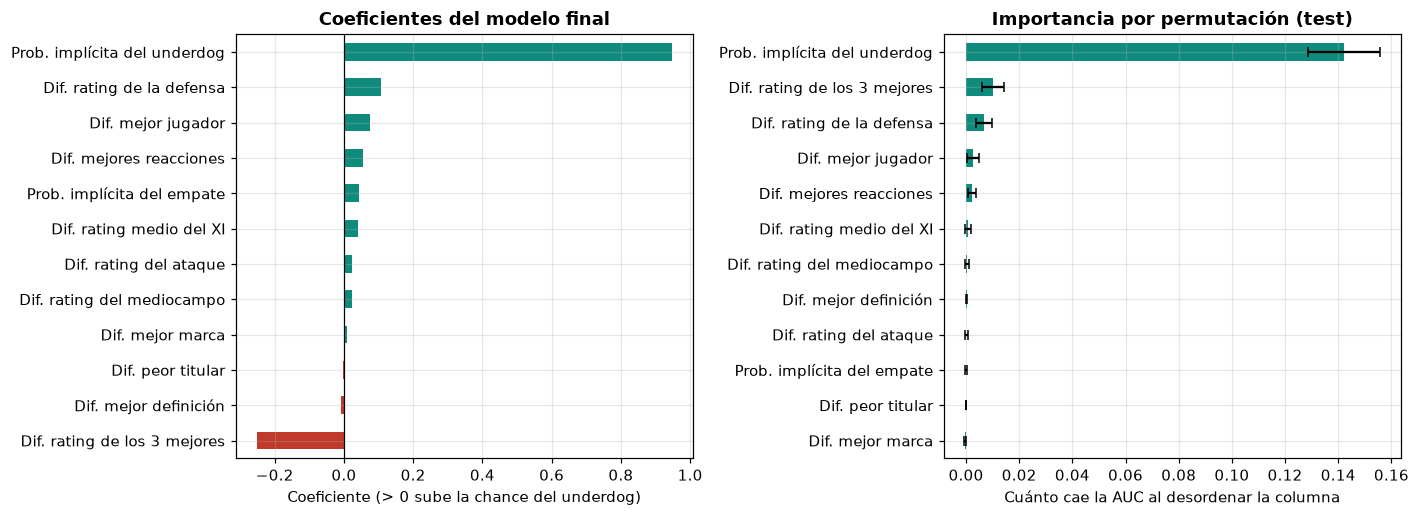

Coeficiente de logit(prob. del underdog): 0.947 | intercepto: -0.075


,coeficiente
Dif. rating de los 3 mejores,-0.2523
Dif. mejor definición,-0.0082
Dif. peor titular,-0.0026
Dif. mejor marca,0.0102
Dif. rating del mediocampo,0.0229
Dif. rating del ataque,0.0246
Dif. rating medio del XI,0.0393
Prob. implícita del empate,0.0441
Dif. mejores reacciones,0.0539
Dif. mejor jugador,0.0751


In [24]:
from sklearn.inspection import permutation_importance

nombres_salida = [n.split("__", 1)[1] for n in modelo_final.named_steps["preparar"].get_feature_names_out()]
coef = pd.Series(modelo_final.named_steps["modelo"].coef_[0], index=legible(nombres_salida)).sort_values()
perm = permutation_importance(modelo_final, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=SEMILLA, n_jobs=-1)
imp = (pd.DataFrame({"caída de AUC": perm.importances_mean, "desvío": perm.importances_std}, index=legible(CANDIDATAS))
         .loc[legible(COLUMNAS_FINALES)].sort_values("caída de AUC"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
coef.plot.barh(ax=axes[0], color=np.where(coef > 0, COLOR["modelo"], COLOR["todos"]))
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Coeficientes del modelo final"); axes[0].set_xlabel("Coeficiente (> 0 sube la chance del underdog)")
imp["caída de AUC"].plot.barh(ax=axes[1], xerr=imp["desvío"], capsize=3, color=COLOR["modelo"])
axes[1].set_title("Importancia por permutación (test)"); axes[1].set_xlabel("Cuánto cae la AUC al desordenar la columna")
plt.tight_layout(); plt.show()
print(f"Coeficiente de logit(prob. del underdog): {coef['Prob. implícita del underdog']:.3f} | intercepto: {modelo_final.named_steps['modelo'].intercept_[0]:.3f}")
coef.round(4).to_frame("coeficiente")

**Cómo se leen.** La probabilidad del mercado (en logit) pesa ~0,95: el modelo parte de la cuota y la corrige. Que sea un
poco menor que 1 quiere decir que **achica las probabilidades extremas**: a los underdogs muy improbables les da un poco más de
lo que dice el mercado, y de ahí salen la mayoría de las apuestas. Los coeficientes de los gaps son chicos, y algunos tienen signo raro («rating de los 3 mejores» negativo) por
**colinealidad**: medio, top 3 y mejor jugador correlacionan 0,86–0,96 y se reparten el peso. Por eso **no se leen de a uno**:
se leen juntos, como «cuánto corrige el XI a la cuota». La permutación lo confirma: sin la probabilidad del mercado la AUC cae al
piso; cada gap solo mueve milésimas.

## Parte 8 — Fuga, lo que no anduvo y el modelo guardado

In [25]:
pd.Series({
    "AUC de la cuota sola (test)": roc_auc_score(y_test, X_test["prob_no_favorito"]),
    "Tope del DAG para una columna sola": 0.90,
    "Brecha AUC train − validación (final)": validacion_final["AUC train"] - validacion_final["AUC media"],
    "AUC al azar − temporal (logística)": azar.loc["Regresión logística", "al azar − temporal"],
    "AUC validación − test (final)": validacion_final["AUC media"] - roc_auc_score(y_test, proba_test),
}).round(4).to_frame("valor")

,valor
AUC de la cuota sola (test),0.6564
Tope del DAG para una columna sola,0.9000
Brecha AUC train − validación (final),-0.0024
AUC al azar − temporal (logística),-0.0025
AUC validación − test (final),-0.0238


La columna que más pesa (la probabilidad del mercado) existe días antes del partido, sola no predice «demasiado bien» y no hay
brechas entre train, validación, test ni validación al azar. **Las cuotas que usa la simulación** no son una feature: el modelo
solo ve la probabilidad normalizada que ya estaba en Silver; la cuota con margen se usa para calcular cuánto se cobra.

In [26]:
pd.DataFrame([
    {"qué probamos": "Árbol, random forest y boosting con grilla", "resultado": "ninguno supera a la logística por más que el desvío; en plata pierden como apostar a ciegas"},
    {"qué probamos": "Elegir por AUC solamente (modelo de 1 columna)", "resultado": "empata en AUC pero nunca apuesta: no sirve para decidir (era la versión anterior)"},
    {"qué probamos": "Las 11 columnas en rojo de la Entrega 2", "resultado": "ninguna mejora la AUC más que su desvío"},
    {"qué probamos": "class_weight='balanced'", "resultado": "misma AUC, probabilidades infladas: apuesta en todos los partidos y pierde como apostar a ciegas"},
    {"qué probamos": "Exigir más valor esperado (5–10%)", "resultado": "menos apuestas y ROI más ruidoso: no mejora de forma estable"},
    {"qué probamos": "Validar al azar", "resultado": "no cambia la AUC: ninguna columna identifica equipo ni fecha"},
]).set_index("qué probamos")

,resultado
qué probamos,
"Árbol, random forest y boosting con grilla",ninguno supera a la logística por más que el desvío; en plata pierden como apostar a ciegas
Elegir por AUC solamente (modelo de 1 columna),empata en AUC pero nunca apuesta: no sirve para decidir (era la versión anterior)
Las 11 columnas en rojo de la Entrega 2,ninguna mejora la AUC más que su desvío
class_weight='balanced',"misma AUC, probabilidades infladas: apuesta en todos los partidos y pierde como apostar a ciegas"
Exigir más valor esperado (5–10%),menos apuestas y ROI más ruidoso: no mejora de forma estable
Validar al azar,no cambia la AUC: ninguna columna identifica equipo ni fecha


In [27]:
# el modelo para la Entrega 4: el pipeline entero, y su fórmula escrita para poder llevarla al navegador
import joblib

MODELOS_DIR = DATA_DIR / "models"
MODELOS_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(modelo_final, MODELOS_DIR / "underdog_modelo.joblib")

prep = modelo_final.named_steps["preparar"]
num = prep.named_transformers_["num"]
columnas_num = [c for c in COLUMNAS_FINALES if c not in PROBABILIDADES]
coefs = dict(zip(nombres_salida, modelo_final.named_steps["modelo"].coef_[0]))
ficha = {
    "modelo": "Regresión logística", "C": C_FINAL, "semilla": SEMILLA, "sklearn": sklearn.__version__,
    "formula": "logit(p) = intercepto + sum(coef_prob * logit(prob)) + sum(coef_j * (x_j - media_j) / desvio_j)",
    "intercepto": float(modelo_final.named_steps["modelo"].intercept_[0]),
    "probabilidades": {c: {"coef": float(coefs[c]), "mediana": float(prep.named_transformers_["prob"].named_steps["imputar"].statistics_[i])}
                       for i, c in enumerate([c for c in COLUMNAS_FINALES if c in PROBABILIDADES])},
    "numericas": {c: {"coef": float(coefs[c]), "media": float(num.named_steps["escalar"].mean_[i]),
                      "desvio": float(num.named_steps["escalar"].scale_[i]),
                      "mediana": float(num.named_steps["imputar"].statistics_[i]),
                      "min_entrenamiento": float(X_train[c].min()), "max_entrenamiento": float(X_train[c].max())}
                  for i, c in enumerate(columnas_num)},
    "regla_de_apuesta": "apostar al underdog si p_modelo * cuota_underdog - 1 > 0",
    "validacion": {"esquema": "TimeSeriesSplit(5)", "auc_media": validacion_final["AUC media"], "auc_desvio": validacion_final["AUC desvío"],
                   "roi": float(plata.loc["Logística mercado + jugadores (12)", "ROI %"]) / 100,
                   "roi_todos": float(plata.loc["Apostar a todos los underdogs", "ROI %"]) / 100},
    "test": {"temporada": TEST_TEMPORADA, "auc": roc_auc_score(y_test, proba_test), "logloss": log_loss(y_test, proba_test),
             "auc_mercado": roc_auc_score(y_test, X_test["prob_no_favorito"]),
             "roi": float(g_test.mean() / APUESTA), "apuestas": int(len(g_test)),
             "roi_todos": float(todas_test.mean() / APUESTA)},
}
(MODELOS_DIR / "underdog_modelo.json").write_text(json.dumps(ficha, indent=2, ensure_ascii=False), encoding="utf-8")

# la fórmula escrita tiene que dar exactamente lo mismo que el pipeline: es lo que va a calcular la app
def formula(fila):
    z = ficha["intercepto"]
    for c, v in ficha["probabilidades"].items():
        z += v["coef"] * logit(fila[c])
    for c, v in ficha["numericas"].items():
        x = v["mediana"] if pd.isna(fila[c]) else fila[c]
        z += v["coef"] * (x - v["media"]) / v["desvio"]
    return 1 / (1 + np.exp(-z))
diferencia_max = np.max(np.abs(X_test.apply(formula, axis=1).values - proba_test.values))
print(f"Diferencia máxima entre la fórmula escrita y el pipeline: {diferencia_max:.2e}")
assert diferencia_max < 1e-9

# las tablas que muestra la app salen de acá, para que la app y el notebook digan lo mismo
def a_registros(t):
    return json.loads(t.reset_index(names="fila").to_json(orient="records", force_ascii=False))
resultados_e3 = {
    "comparacion": a_registros(comparacion[["AUC media", "AUC desvío", "AUC train", "log-loss media", "Δ AUC % vs logística"]]),
    "grupos": a_registros(t_grupos[["AUC media", "AUC desvío", "Δ AUC vs prob. sola", "desvío de Δ"]]),
    "plata": a_registros(plata[["apuestas", "% de partidos", "ROI %", "IC 95% ROI"]]),
    "plata_por_pedazo": a_registros(pd.DataFrame(por_pedazo).T),
    "test": a_registros(test_tabla[["AUC", "log-loss", "apuestas", "ROI %"]].astype(str)),
    "barrido_logistica": a_registros(curvas["Regresión logística"]),
    "coeficientes": a_registros(coef.round(4).to_frame("coeficiente")),
    "oof_modelo": {str(k): float(v) for k, v in oof["Logística mercado + jugadores (12)"].items()},
    "oof_indices_match_id": entrenamiento.loc[oof["Logística mercado + jugadores (12)"].index, "match_id"].astype(int).tolist(),
}
(MODELOS_DIR / "resultados_e3.json").write_text(json.dumps(resultados_e3, ensure_ascii=False), encoding="utf-8")
print("resultados exportados:", ", ".join(resultados_e3))

Diferencia máxima entre la fórmula escrita y el pipeline: 1.94e-16
resultados exportados: comparacion, grupos, plata, plata_por_pedazo, test, barrido_logistica, coeficientes, oof_modelo, oof_indices_match_id


## Conclusión

- **Ordenar partidos**: ningún modelo le gana al mercado (AUC ~0,64 en validación, ~0,66 en test, contra 0,5 del piso). Las
  cuotas ya saben casi todo lo que dicen los ratings de los titulares.
- **Tomar decisiones**: el modelo con jugadores es el único que cambia decisiones sin perder plata. Apostar a ciegas a los
  underdogs pierde ~7,7% (el margen de la casa); apostar solo donde el modelo ve valor queda **cerca de empatar**, con un
  intervalo que incluye el cero. **No le ganamos a las casas de apuestas, pero dejamos de perder contra ellas.**
- **El modelo final** es una regresión logística con 12 columnas, cuya fórmula está escrita en `underdog_modelo.json` y
  verificada contra el pipeline: es la que calcula la aplicación de la Entrega 4.